In [11]:
# Libraries
import numpy as np
import pyarrow.parquet as pq
import os
import pyarrow.csv as pv
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import sys 
sys.path.append('../')
from src.mstl import SeasonalTrendDecomp as mstl
from sklearn.model_selection import train_test_split
from src.isolation_forest import IsolationForestAnomalyDetector
from sklearn.ensemble import IsolationForest as SkIsolationForest   # aliased: a class named IsolationForest below would shadow it


In [12]:
df_modelling = pd.read_parquet('../data/modelling/df_modelling.parquet', engine='pyarrow')
df_modelling = df_modelling.set_index('timestamp')

In [3]:
df_modelling

,nd,timestamp,embedded_solar_generation,embedded_wind_generation,year,month,weekday,half_hour_intervals
0,25593,2018-01-01 00:00:00+00:00,0,3064,2018,1,0,0
1,26349,2018-01-01 00:30:00+00:00,0,3005,2018,1,0,1
2,26240,2018-01-01 01:00:00+00:00,0,2950,2018,1,0,2
3,25292,2018-01-01 01:30:00+00:00,0,2895,2018,1,0,3
4,24416,2018-01-01 02:00:00+00:00,0,2892,2018,1,0,4
...,...,...,...,...,...,...,...,...
105163,25269,2023-12-31 21:30:00+00:00,0,2707,2023,12,6,43
105164,24254,2023-12-31 22:00:00+00:00,0,2734,2023,12,6,44
105165,23455,2023-12-31 22:30:00+00:00,0,2761,2023,12,6,45
105166,22533,2023-12-31 23:00:00+00:00,0,2767,2023,12,6,46


create PD SERIES which is put into mstl (for initial anomaly detection through trend isolation (seasonal))

In [4]:
df = pd.Series(data = df_modelling['nd'].values, index = df_modelling['timestamp'])

In [ ]:
type(df) # pandas series generated with tiemstamp as index for the MSTl 

pandas.Series

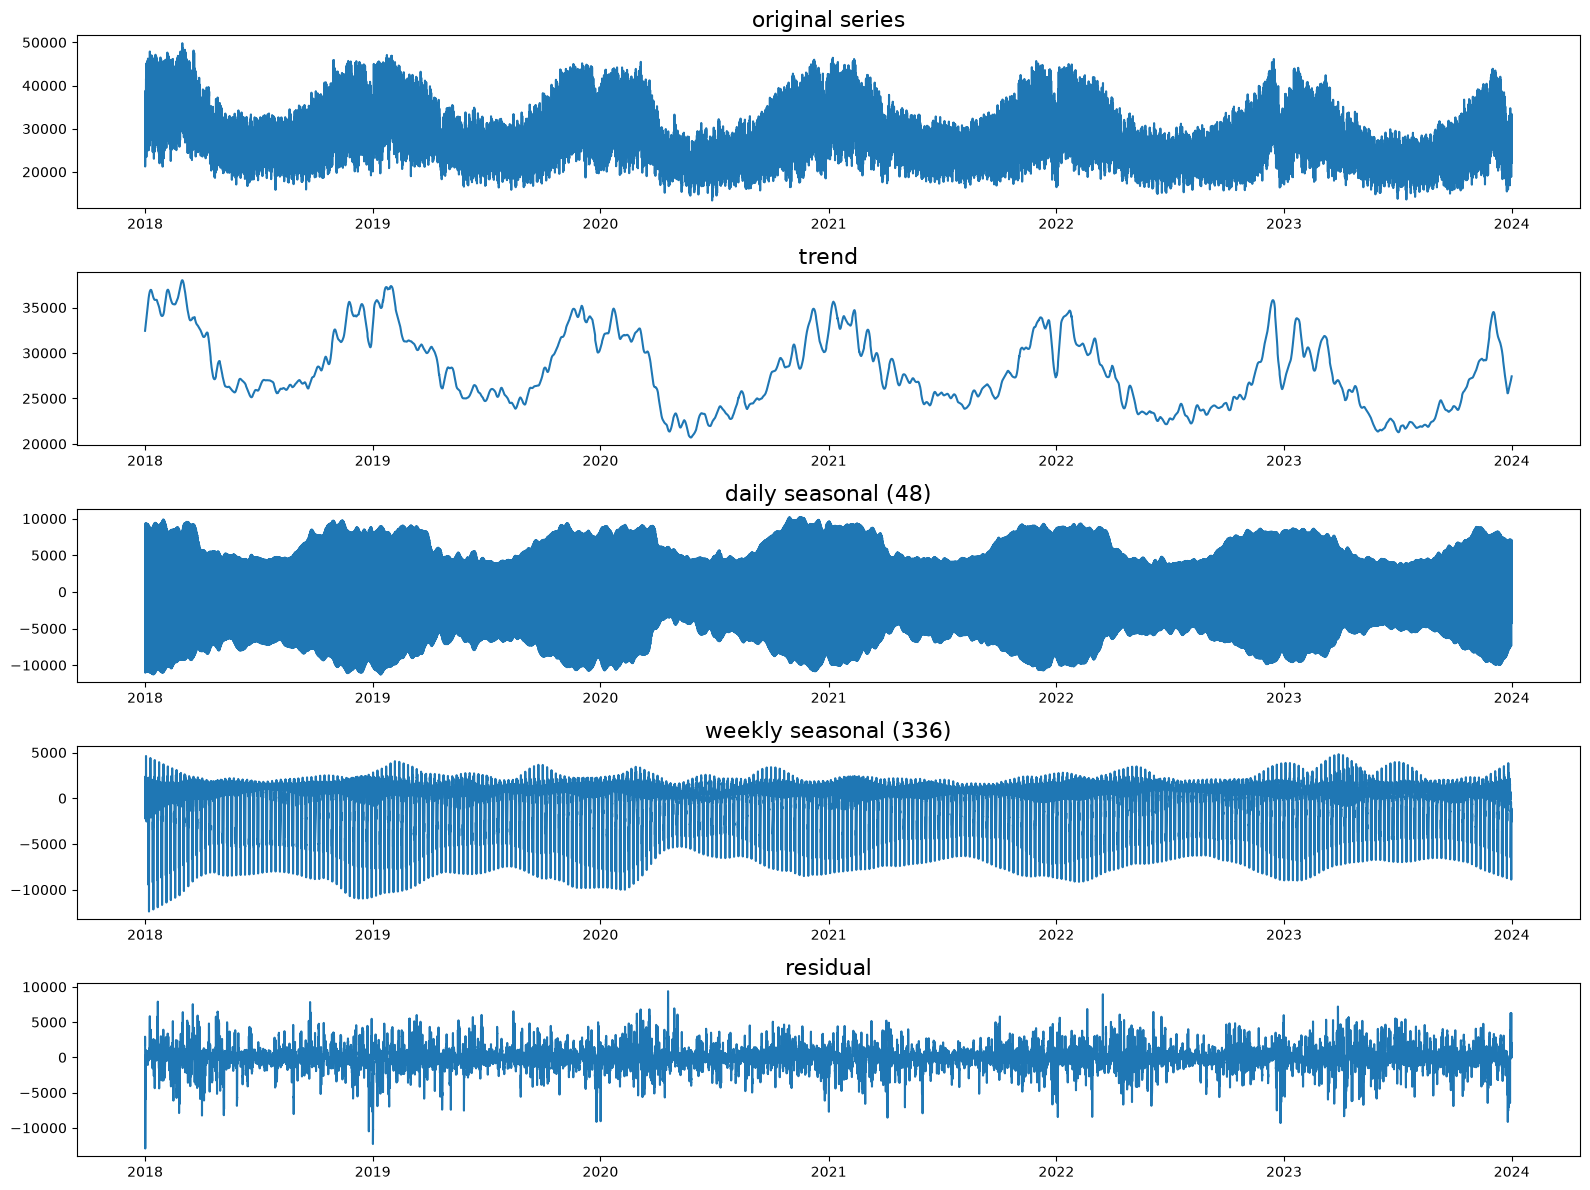

In [11]:
mstl = mstl(df)
seasonal, trend, resid = mstl.mstl_model_train()
mstl.plot(seasonal, trend, resid)


In [13]:
# combine all outputs into one table with axis = columns and timestamps as an index (similar to df)
mstl_output = pd.concat([trend, seasonal, resid], axis=1)
mstl_output.columns = ['trend', 'seasonal_daily', 'seasonal_weekly', 'residual']

# Make sure the folder exists, then save (keep the timestamp index)
mstl_output.to_parquet('../data/modelling/mstl_output.parquet', engine='pyarrow', index=True)

In [16]:
mstl_output = pd.read_parquet('../data/modelling/mstl_output.parquet', engine='pyarrow')

In [ ]:
mstl_output.shape # 105168
df_modelling.shape # 105168

# the number of rows should match since they will be merged 

(105168, 7)

## ND = trend + daily + weekly + residual
- Trend: the general demand level around that time, the slow-moving baseline. For example, 28,000 MW.
- Daily seasonal: how much that time of day pushes demand above or below the trend. Positive at 18:00 (+11,000), negative at 04:00 (−6,500).
- Weekly seasonal: the extra push from that day of the week. Slightly positive on weekdays, negative at weekends (−1,500 on a Saturday evening).
- Residual: what’s left over:



Relevance to anomaly detection:

- Trend: a different value on every row, but it changes very slowly, like a smooth line. It drifts higher in winter, lower in summer, and slowly down over the years. It doesn’t repeat.
- Daily seasonal: nearly the same value at the same time each day. 18:00 today ≈ 18:00 yesterday. It repeats roughly every 48 rows and changes slowly with the seasons.
- Weekly seasonal: nearly the same value on the same day each week. This Saturday ≈ last Saturday. It repeats roughly every 336 rows.
- Residual: a completely different value on every row, jumping around with no pattern. This is where anomalies show up.

Combine the residual column (since it will be used for anomaly detection) with the df_modelling dataset
- worth keeping the trend and seasonal columns to for metadata, but do not include it the anomaly detection model

In [27]:
# join both dataframes using index to align for correct order of rows, ensure that all values are included 
mstl_modelling_df= pd.merge(df_modelling, mstl_output, left_index=True, right_index=True, how='outer')
mstl_modelling_df.shape # 105168 correct number of rows therefore merge was successful 

(105168, 11)

In [28]:
# prevent having to reload entire file, save the resulting df for modellig and efficience downstream
mstl_modelling_df.to_parquet('../data/modelling/mstl_modelling_df.parquet', engine='pyarrow', index=True)

In [4]:
mstl_modelling_df= pd.read_parquet('../data/modelling/mstl_modelling_df.parquet', engine = 'pyarrow')

In [ ]:
mstl_modelling_df.isna().sum() # no missing values !


nd                           0
embedded_solar_generation    0
embedded_wind_generation     0
year                         0
month                        0
weekday                      0
half_hour_intervals          0
trend                        0
seasonal_daily               0
seasonal_weekly              0
residual                     0
dtype: int64

Check to ensure that the sum of trend, daily weekly and residual = ND

In [ ]:
(mstl_modelling_df.nd - (mstl_modelling_df.trend + mstl_modelling_df.seasonal_daily + mstl_modelling_df.seasonal_weekly+ mstl_modelling_df.residual)).abs()

(mstl_modelling_df.nd - (mstl_modelling_df.trend + mstl_modelling_df.seasonal_daily + mstl_modelling_df.seasonal_weekly+ mstl_modelling_df.residual)).max
# maximum value is tiny meaning that the daily, weekly adn residual all add up to rouhgly ND 


<bound method Series.max of timestamp
2018-01-01 00:00:00+00:00    3.637979e-12
2018-01-01 00:30:00+00:00    3.637979e-12
2018-01-01 01:00:00+00:00   -7.275958e-12
2018-01-01 01:30:00+00:00   -3.637979e-12
2018-01-01 02:00:00+00:00   -7.275958e-12
                                 ...     
2023-12-31 21:30:00+00:00    0.000000e+00
2023-12-31 22:00:00+00:00    0.000000e+00
2023-12-31 22:30:00+00:00    0.000000e+00
2023-12-31 23:00:00+00:00    0.000000e+00
2023-12-31 23:30:00+00:00    0.000000e+00
Length: 105168, dtype: float64>

ISOLATION FOREST, KNN CLUSTERS,  AND PCA - all unsupervised techniques
- split data 
- build models in src file 
- run  

In [5]:
# no labels so no y_train, y_val, y_test
# 70% of data is used for training the rest is validation and test (split 50%, so 70:15:15)
x_train, x_remain = train_test_split(mstl_modelling_df, test_size=0.30, random_state=42)
x_val, x_test = train_test_split(x_remain, test_size=0.50, random_state=42)

Isolation Forest

In [12]:
if_ad = IsolationForestAnomalyDetector(x_train, x_val, x_test, contamination='auto', n_estimators = 100)
if_ad.train()
if_ad.evaluate_train()
x_val_preds, x_val_raw_scores, x_val_decision_scores, x_val_scores = if_ad.validate()


Training unsupervised anomaly detection isolation forest model...
Building estimator 1 of 12 for this parallel run (total 100)...
Building estimator 2 of 12 for this parallel run (total 100)...
Building estimator 1 of 13 for this parallel run (total 100)...
Building estimator 1 of 12 for this parallel run (total 100)...
Building estimator 1 of 13 for this parallel run (total 100)...
Building estimator 1 of 12 for this parallel run (total 100)...
Building estimator 1 of 13 for this parallel run (total 100)...
Building estimator 1 of 12 for this parallel run (total 100)...
Building estimator 1 of 13 for this parallel run (total 100)...
Building estimator 2 of 13 for this parallel run (total 100)...
Building estimator 2 of 13 for this parallel run (total 100)...
Building estimator 2 of 13 for this parallel run (total 100)...
Building estimator 2 of 13 for this parallel run (total 100)...
Building estimator 2 of 12 for this parallel run (total 100)...
Building estimator 2 of 12 for this pa

[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.


Building estimator 4 of 13 for this parallel run (total 100)...
Building estimator 5 of 12 for this parallel run (total 100)...
Building estimator 4 of 12 for this parallel run (total 100)...
Building estimator 3 of 12 for this parallel run (total 100)...
Building estimator 4 of 13 for this parallel run (total 100)...
Building estimator 4 of 13 for this parallel run (total 100)...
Building estimator 5 of 13 for this parallel run (total 100)...
Building estimator 5 of 12 for this parallel run (total 100)...
Building estimator 6 of 12 for this parallel run (total 100)...
Building estimator 5 of 13 for this parallel run (total 100)...
Building estimator 4 of 12 for this parallel run (total 100)...
Building estimator 6 of 13 for this parallel run (total 100)...
Building estimator 5 of 13 for this parallel run (total 100)...
Building estimator 7 of 13 for this parallel run (total 100)...
Building estimator 6 of 13 for this parallel run (total 100)...
Building estimator 5 of 12 for this para

[Parallel(n_jobs=8)]: Done   3 out of   8 | elapsed:    0.6s remaining:    1.0s
[Parallel(n_jobs=8)]: Done   8 out of   8 | elapsed:    0.6s finished
[Parallel(n_jobs=1)]: Done  40 tasks      | elapsed:    0.5s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    1.4s finished
[Parallel(n_jobs=1)]: Done  40 tasks      | elapsed:    0.5s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    1.6s finished
[Parallel(n_jobs=1)]: Done  40 tasks      | elapsed:    0.5s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    1.3s finished


train          73,617 rows | 19,923 flagged (27.06%) | score min -0.6378 median -0.4768 max -0.4022


[Parallel(n_jobs=1)]: Done  40 tasks      | elapsed:    0.1s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.5s finished
[Parallel(n_jobs=1)]: Done  40 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.2s finished
[Parallel(n_jobs=1)]: Done  40 tasks      | elapsed:    0.0s


validation     15,775 rows |  4,369 flagged (27.70%) | score min -0.6272 median -0.4771 max -0.4037


[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.2s finished


[Parallel(n_jobs=1)]: Done  40 tasks      | elapsed:    0.2s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.4s finished


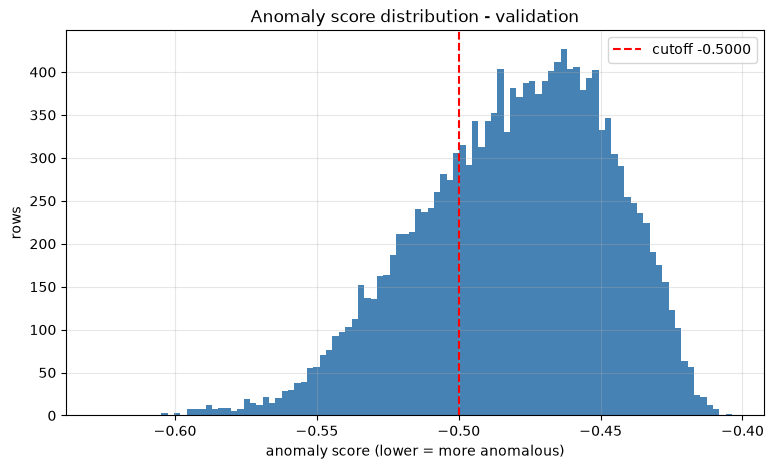

array([-0.4675878 , -0.44184001, -0.47646634, ..., -0.51038193,
       -0.4474529 , -0.54826553], shape=(15775,))

In [8]:
if_ad.plot_score_distribution(x_val)